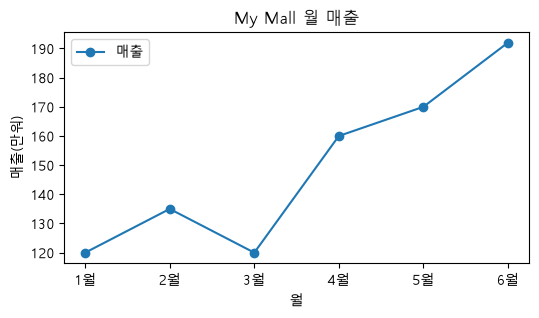

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns # 통계 그래프 라이브러리
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"   # Windows OS
# plt.rcParams["font.family"] = "AppleGothic"     # 맥 OS

# Figure(캔버스), Axes(그래프)
fig, ax = plt.subplots(figsize=(6, 3))
# X축 데이터 (월)
months = ["1월", "2월", "3월", "4월", "5월", "6월"]
# Y축 데이터 (매출액, 만원)
sales = [120, 135, 120, 160, 170, 192]

# 선 그래프
ax.plot(months, sales, marker="o", label="매출")
ax.set_title("My Mall 월 매출")     # 그래프 제목
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()                         # 범례 표시
plt.show()                          # 차트 그리기

In [6]:
import pandas as pd
house = pd.read_csv("./datasets/usa_housing.csv")
print(house.shape)
house

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4
...,...,...,...,...,...,...,...,...,...,...
295,862002,4,2.8,1129,1944,0,1.80,35227,32.30,3
296,242483,3,2.4,4440,1988,2,0.46,15978,99.71,9
297,758271,2,2.2,4694,1952,2,0.71,97527,97.98,7
298,314835,5,2.0,4907,1941,3,0.53,27153,65.61,8


In [ ]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

(10, 10)

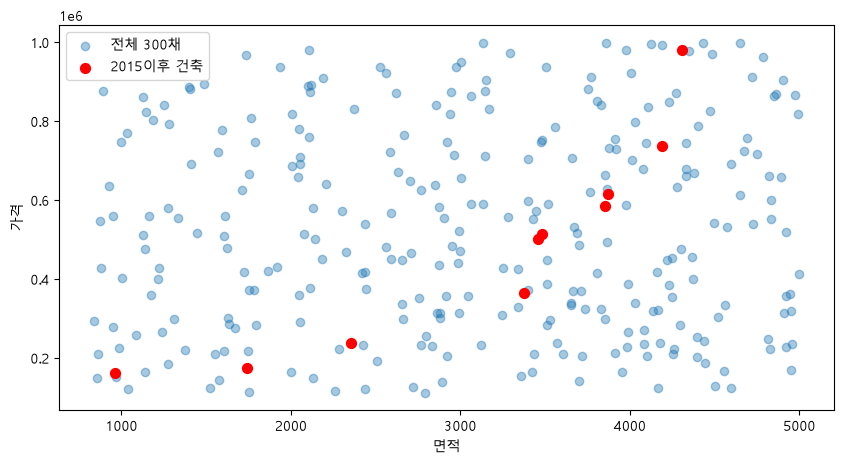

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채") # 산점도
plt.scatter(small["SquareFeet"], small["Price"], color="red", s=50, label="2015이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()

# 2025이후 건축 산점도(10)를 보니 추세선 같은게 보인다. 상관계수가 1에 가까울 것이다.
# corr: 상관계수를 구하는 메서드
# 우상향: 양의 상관관계
# 우하향: 음의 상관관계
print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]), 2))
# 전체 300채의 상관계수: 0.08

print("10채의 상관계수:", round(house["SquareFeet"].corr(small["Price"]), 2))
# 10채의 상관계수: 0.89 -> 강한 양의 선형 상관관계

In [27]:
# RNG: Random Number Generator(난수 생성기)
# 파라미터로 시드(seed) 전달: 난수 발생 시 참고하는 데이터. 동일한 seed 값을 적용하는 항상 동일한 난수가 발생
rng = np.random.default_rng(40)

n = 200

# [균등분포 Uniform]
# rng.uniform(low, high, size): 지정한 범위에서 균등분포(Uniform Distribution)를 따르는 실수 난수를 생성
area = rng.uniform(20, 85, n) # 20 이상 85 미만에서 균등하게 n개만큼 난수 발생
area

# [정규분포 Normal]
# y = wx + b
# w: 기울기 450 임의 지정
# b: 편향(y절편) 5000 임의 지정
# 노이즈(오차값)를 줘서 흩뿌려지게 한다. 하지만 우상향을 벗어나지는 않음

# x축이 area, y축이 price
# 정규분포를 따르는 실수 난수 생성 메서드 rng.normal(loc, scale, size)
price = (area * 450 + 5000 + (rng.normal(0, 2500, n))).round(-1) # 소수점 이하 자르기
price

# [무작위 표본 추출 Random Sampling]
# rng.choice(a, size, replace): 주어진 데이터에서 무작위로 표본을 추출
# 특이 매물 5건 생성
special = rng.choice(n, 5, replace=False) # replace=False: 중복을 허용하지 않는 비복원 추출
price[special] += rng.uniform(15000, 25000, 5).round(-1) # NOTE: (1.5억~ 2.5억)
special

office = pd.DataFrame({"area": area, "price": price})
office.describe().round(-1)

,area,price
count,200.0,200.0
mean,50.0,29140.0
std,20.0,9110.0
min,20.0,11400.0
25%,40.0,21620.0
50%,50.0,28960.0
75%,70.0,36380.0
max,80.0,58460.0


In [28]:
# 파일 저장
office.to_csv("./datasets/office.csv", index=False)

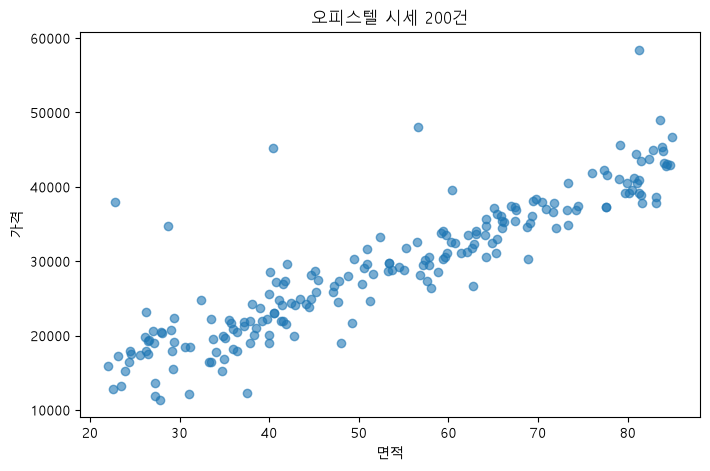

상관계수: 0.8963336215680755


In [31]:
# 산점도 차트

# 캔버스(Figure) 생성
plt.figure(figsize=(8, 5))
plt.scatter(office["area"], office["price"], alpha=0.6)
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [ ]:
from sklearn.linear_model import LinearRegression

# 선형 회귀 모델 만들기
model = LinearRegression()

# 학습: X(입력), y(정답)
# X (Feature Matrix): 입력 특성들을 담은 2차원 행렬
# y (Target Vector): 각 데이터에 대응하는 정답을 담은 1차원 벡터
X = office[["area"]]
y = office["price"]

model.fit(X, y)

print(f"기울기 w = {model.coef_[0]} 정답: 450")
# 기울기 w = 439.45870417134705 정답: 450
print(f"절편 b = {model.intercept_} 정답: 5000")
# 절편 b = 5926.680580056112 정답: 5000

기울기 w = 439.45870417134705 정답: 450
절편 b = 5926.680580056112 정답: 5000


오후 (26.11.24)

In [ ]:
# 33, 59 가격 예측
new = pd.DataFrame({"area": [33, 59]})
model.predict(new).round(-1)

array([20430., 31850.])

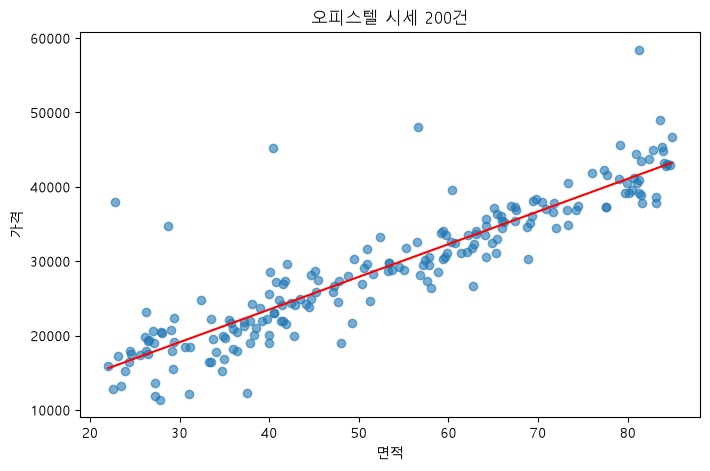

상관계수: 0.8963336215680755


In [37]:
# 학습한 모델로 예측하기
y_pred = model.predict(X)
line = X.sort_values("area")
line_pred = model.predict(line)

# 캔버스(Figure) 생성
plt.figure(figsize=(8, 5))
# 산점도 차트
plt.scatter(office["area"], office["price"], alpha=0.6, label="실제 시세")
# 모델의 직선
plt.plot(line["area"], line_pred, color="red", label="모델의 직선")

# 타이틀과 x, y 레이블
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [48]:
# MAE(평균절대오차), MSE(평균제곱오차), RMSE(), R_SCORE
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# MAE: 오차 절댓값의 평균 -> 평균적으로 얼마만큼 틀리나?
print(f"MAE = {mean_absolute_error(y, y_pred):,.0f}")
# MAE = 2492.503948887723

# MSE: 오차 제곱의 평균 (단위 제곱)
print(f"MSE = {mean_squared_error(y, y_pred):,.0f}")
# MSE = 16,240,971

# RMSE: 오차 제곱 평균의 루트 (원래 단위)
print(f"RMSE = {root_mean_squared_error(y, y_pred):,.0f}")
# RMSE = 4,030

# R Score: 0 ~ 1
print(f"R_SCORE = {r2_score(y, y_pred):,.3f}")
# R_SCORE = 0.803

MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE = 0.803


In [54]:
normal = np.ones(len(office), dtype=bool)
normal[special] = False
print("특이매물", special)
print("정상매물", normal.sum())
normal

특이매물 [53 13  2 92 71]
정상매물 195


array([ True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [66]:
# [특이 매물을 포함했을 때와 제외했을 때의 예측 오차를 비교]

all_rows = np.ones(len(office), dtype=bool)
cases = [("전체 200건", all_rows), ("특이매물 제외 195건", normal)]

for name, mask in cases:
    y_true = y[mask]        # 실제 가격
    y_hat = y_pred[mask]    # 예측 가격

    # MAE: 오차 절댓값의 평균
    mae = mean_absolute_error(y_true, y_hat)
    # RMSE
    rmse = root_mean_squared_error(y_true, y_hat)
    # R2
    r2 = r2_score(y_true, y_hat)
    print(f"{name} MAE {mae:,.3f} | RMSE {rmse:,.3f} | RScore {r2:,.4f}")

전체 200건 MAE 2,492.504 | RMSE 4,030.009 | RScore 0.8034
특이매물 제외 195건 MAE 2,075.104 | RMSE 2,731.535 | RScore 0.9024
